# Hepatitis C category - JarvisTEC (`hepatitis`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [Hepatitis C Prediction Dataset (Kaggle, fedesoriano/hepatitis-c-dataset)](https://www.kaggle.com/datasets/fedesoriano/hepatitis-c-dataset), a copy of the *HCV data* set of the UCI Machine Learning Repository (Lichtinghagen, Klawonn & Hoffmann).

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "hepatitis"
# CSV path relative to training/<name>/ (data/ is git-ignored).
DATA_PATH = "../../data/hepatitis/HepatitisCdata.csv"
TARGET_COLUMN = "category"  # cleaned in section 2
TASK_TYPE = "classification"  # "classification" or "regression"
IS_TIME_SERIES = False  # True for bitcoin, avocado...: chronological split
DATE_COLUMN = None  # date column name when IS_TIME_SERIES is True
# No extra column to exclude: the row index is dropped in section 2.
EXCLUDED_COLUMNS = []
SEED = 42
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)
assert TASK_TYPE in ("classification", "regression")

## 1. Problem analysis

The goal is to estimate, from **routine blood test values** plus age and sex, which group a person belongs to: a healthy **blood donor**, or a hepatitis C patient in one of three groups of increasing liver damage (**hepatitis**, **fibrosis**, **cirrhosis**), referred to below as disease stages. Staging liver damage normally requires a biopsy or specialized tests; a model that reads a standard laboratory panel could help a laboratory decide which samples deserve a closer look. The output is an **estimate to support that decision, never a diagnosis**.

- **Task type:** multiclass classification with four classes and a **strong imbalance**: 87.7 % of the patients are blood donors and each disease stage has between 21 and 30 patients.
- **Success metrics:** **macro F1** (the F1 of the four classes averaged with equal weight) and **balanced accuracy** (the mean recall of the four classes). Plain accuracy is misleading here: a model that always answers "blood donor" is right 87.7 % of the time and finds no patient. The per-class report and the confusion matrix are read together with these metrics, and the model is always compared with a baseline that predicts the most frequent class.
- **Cost of each error (an assumption):** the two kinds of error are not equally serious. A **patient classified as a healthy donor** is the costly one: the sample gets no closer look and the disease may go unnoticed. A **healthy donor flagged as a patient** costs a confirmatory test and some worry, which is cheaper. This ranking is assumed for this project; it was not quantified with a laboratory. It is the reason for the metrics above: macro F1 and balanced accuracy give each disease class the same weight as the donors, so missed patients are not hidden by the donor majority, and section 5 also counts how many patients were predicted as donors and how many donors were flagged. Class weights are tried for the same reason. The decision threshold itself is not tuned for this cost (see the future improvements).
- **Support:** Hoffmann et al. (2018), the authors of the dataset, used these same laboratory values to build diagnostic pathways with machine learning. He and Garcia (2009) describe why accuracy fails with imbalanced classes and why class-weighted learning helps.

## 2. Data understanding

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (615, 14)


,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


In [3]:
# The first, unnamed column is only a row number: it is dropped.
df = df.drop(columns=df.columns[0])
# snake_case names: the same fields the API receives
# (backend/models/hepatitis/schema.py).
df.columns = [c.strip().lower() for c in df.columns]

# Clean class labels, ordered from healthy to most advanced liver damage.
CLASS_LABELS = {
    "0=Blood Donor": "blood_donor",
    "0s=suspect Blood Donor": "suspect_donor",
    "1=Hepatitis": "hepatitis",
    "2=Fibrosis": "fibrosis",
    "3=Cirrhosis": "cirrhosis",
}
CLASS_ORDER = ["blood_donor", "hepatitis", "fibrosis", "cirrhosis"]
print("Original categories:")
display(df[TARGET_COLUMN].value_counts().rename("patients"))
df[TARGET_COLUMN] = df[TARGET_COLUMN].map(CLASS_LABELS)
assert df[TARGET_COLUMN].notna().all()

# "Suspect" donors have no confirmed label (see the data description):
# they are set aside and never used to train or to score the model.
suspects = df[df[TARGET_COLUMN].eq("suspect_donor")].copy()
df = df[df[TARGET_COLUMN].ne("suspect_donor")].reset_index(drop=True)
print("Suspect donors set aside:", len(suspects))
print("Rows, columns kept:", df.shape)
display(df.head())

Original categories:


category
0=Blood Donor             533
3=Cirrhosis                30
1=Hepatitis                24
2=Fibrosis                 21
0s=suspect Blood Donor      7
Name: patients, dtype: int64

Suspect donors set aside: 7
Rows, columns kept: (608, 13)


,category,age,sex,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
0,blood_donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,blood_donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,blood_donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,blood_donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,blood_donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(summary)
print("Duplicated rows:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,% missing,unique
category,str,0,0.00,4
age,int64,0,0.00,49
sex,str,0,0.00,2
alb,float64,1,0.16,183
alp,float64,18,2.96,409
alt,float64,1,0.16,336
ast,float64,0,0.00,292
bil,float64,0,0.00,187
che,float64,0,0.00,401
chol,float64,10,1.64,309


Duplicated rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
category,608,4,blood_donor,533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,608.0,NaN,NaN,NaN,47.291118,9.992705,19.0,39.0,47.0,54.0,77.0
sex,608,2,m,371,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alb,607.0,NaN,NaN,NaN,41.818781,5.406717,20.0,39.0,42.0,45.25,82.2
alp,590.0,NaN,NaN,NaN,67.821017,25.274423,11.3,52.5,66.0,79.525,416.6
alt,607.0,NaN,NaN,NaN,27.601318,21.227539,0.9,16.4,23.0,32.75,258.0
ast,608.0,NaN,NaN,NaN,34.369408,32.622442,12.0,21.6,25.85,32.8,324.0
bil,608.0,NaN,NaN,NaN,11.474013,19.770558,1.8,5.3,7.3,11.3,254.0
che,608.0,NaN,NaN,NaN,8.204885,2.1684,1.42,6.95,8.27,9.585,16.41
chol,598.0,NaN,NaN,NaN,5.378829,1.119394,1.43,4.62,5.3,6.075,9.67


In [5]:
# Where are the missing values, and what do the set-aside rows look like?
print("Rows with at least one missing value:", df.isna().any(axis=1).sum())
display(
    df.drop(columns=TARGET_COLUMN).isna()
    .groupby(df[TARGET_COLUMN]).sum()
    .loc[CLASS_ORDER, lambda t: t.sum() > 0]
    .rename_axis("missing values per class")
)
print("Suspect donors (not used for training or testing):")
display(suspects.drop(columns=TARGET_COLUMN))

Rows with at least one missing value: 26


,alb,alp,alt,chol,prot
missing values per class,,,,,
blood_donor,0,0,0,7,0
hepatitis,0,3,1,0,0
fibrosis,0,9,0,1,0
cirrhosis,1,6,0,2,1


Suspect donors (not used for training or testing):


,age,sex,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
533,47,m,22.5,124.0,79.5,46.7,2.3,6.83,4.30,170.0,345.6,58.6
534,48,m,24.9,116.9,49.2,24.3,4.9,3.44,5.25,29.0,83.0,47.8
535,49,m,21.6,42.2,9.5,10.6,2.4,3.75,3.01,64.0,38.9,44.8
536,55,m,47.3,106.0,208.8,130.6,0.8,14.80,8.08,76.0,71.6,78.3
537,71,m,14.9,69.8,19.7,95.2,9.8,13.30,2.61,9.0,7.6,47.0
538,74,m,20.3,84.0,22.8,43.0,5.7,4.91,3.19,52.0,218.3,47.8
539,59,f,19.3,208.2,325.3,146.6,6.9,5.33,4.72,32.0,295.6,53.1


**Data description.** Laboratory values of blood donors and hepatitis C patients (UCI *HCV data*). The CSV has **615 rows** and 14 columns; the first column is only a row number and is dropped, which leaves the target and 12 inputs:

| Variable | Meaning | Type / assumed unit |
|---|---|---|
| `category` | diagnosis group (**target**) | 5 original values, see below |
| `age` | age | years, 19-77 |
| `sex` | sex | categorical: `m`, `f` |
| `alb` | albumin | g/L |
| `alp` | alkaline phosphatase | U/L |
| `alt` | alanine aminotransferase | U/L |
| `ast` | aspartate aminotransferase | U/L |
| `bil` | bilirubin | µmol/L |
| `che` | cholinesterase | kU/L |
| `chol` | cholesterol | mmol/L |
| `crea` | creatinine | µmol/L |
| `ggt` | gamma-glutamyl transferase | U/L |
| `prot` | total protein | g/L |

**The laboratory units are an assumption.** The source file does not document them; the units above are the usual reporting units for these tests and are consistent with the value ranges (for example a median albumin of 42 and a median creatinine of 77), but they have not been confirmed against a primary source. For that reason the values are quoted without units in the rest of the notebook.

**Target.** The original `Category` has five values: `0=Blood Donor` (533), `0s=suspect Blood Donor` (7), `1=Hepatitis` (24), `2=Fibrosis` (21) and `3=Cirrhosis` (30). The four confirmed groups are renamed to `blood_donor`, `hepatitis`, `fibrosis` and `cirrhosis`.

**The 7 "suspect" donors are removed** from training and testing, which leaves **608 patients**. Reasons:
- Their label is not a confirmed state: they are neither confirmed healthy donors nor confirmed hepatitis C patients, and the source does not document the criterion.
- With 7 rows, a stratified 80/20 split would leave 1 or 2 of them in the test set: the class could be neither learned nor evaluated.
- Merging them into `blood_donor` would add atypical profiles to the healthy class: 6 of the 7 have an albumin between 14.9 and 24.9, while the donors' median is 42.2.

They are set aside and used only in section 5, as a qualitative check of what the model answers for them.

**Data quality:**
- **Missing values:** 31 values in 5 columns, spread over 26 rows: `alp` 18 (2.96 %), `chol` 10 (1.64 %), and one each in `alb`, `alt` and `prot`. They are imputed with the median inside the `Pipeline`, so no patient is lost and the backend tolerates a missing value.
- **Missingness is not random:** all 18 missing `alp` values belong to patients with disease (9 of the 21 fibrosis patients lack it) and none to donors. A "value is missing" indicator would probably raise the scores, but it would capture how the data was collected rather than biology, so it is deliberately **not** added.
- **Duplicates:** none.
- **Extreme values:** very long right tails (creatinine up to 1079.1 with a median of 77; GGT up to 650.9; bilirubin up to 254). These values are plausible for sick patients and are kept.
- **Sex:** 371 men and 237 women.

## 3. Data exploration

category
blood_donor    87.66
cirrhosis       4.93
hepatitis       3.95
fibrosis        3.45
Name: % of each class, dtype: float64

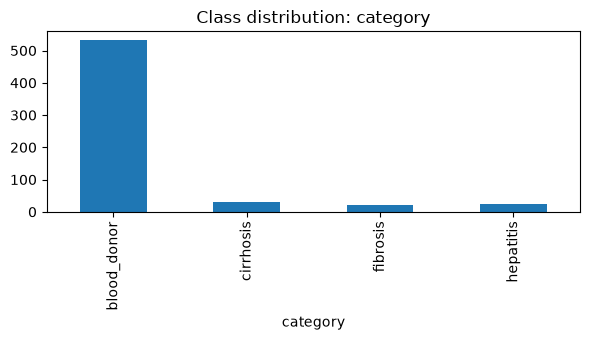

In [6]:
target = TARGET_COLUMN
fig, ax = plt.subplots(figsize=(6, 3.5))
if TASK_TYPE == "classification":
    df[target].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(f"Class distribution: {target}")
    shares = (df[target].value_counts(normalize=True) * 100).round(2)
    display(shares.rename("% of each class"))
else:
    df[target].plot(kind="hist", bins=40, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

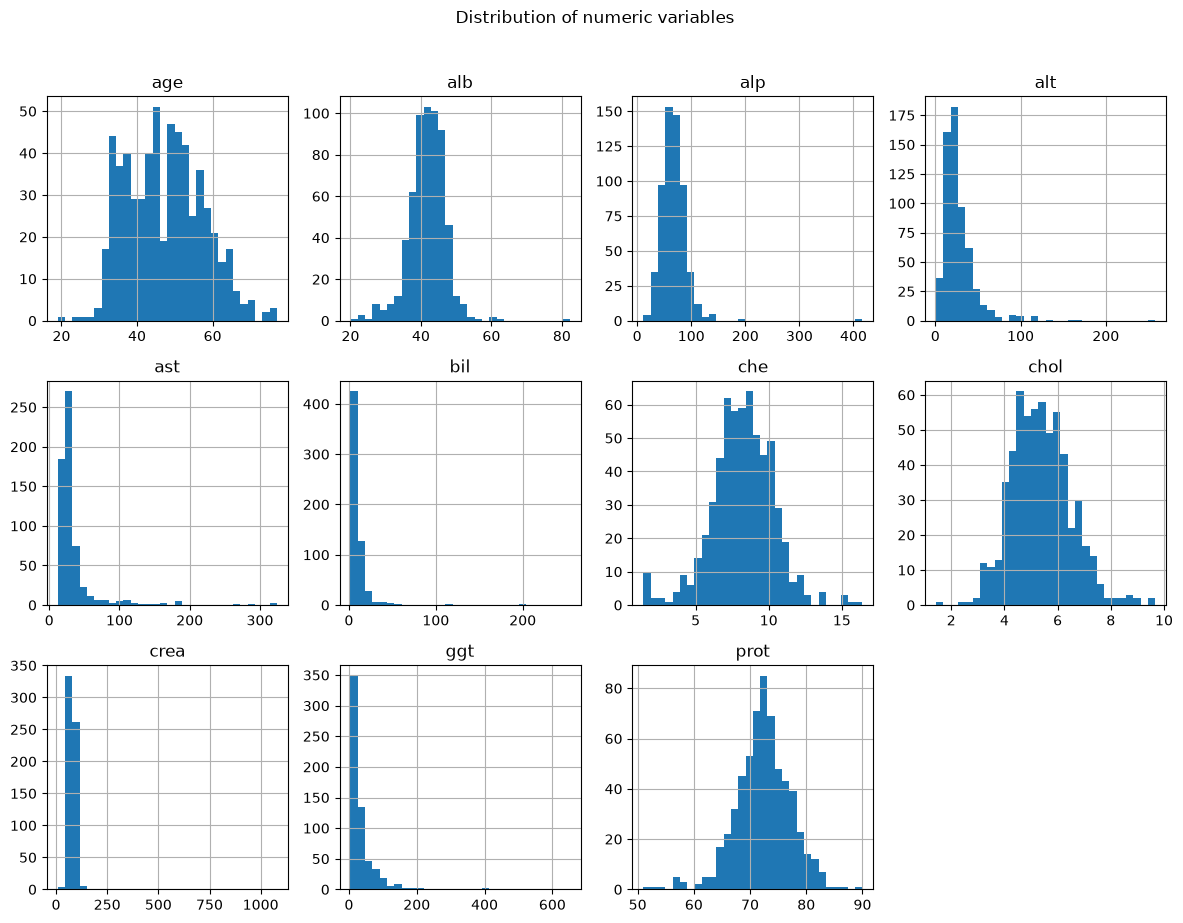

In [7]:
numeric_columns = [
    c for c in df.select_dtypes("number").columns
    if c not in EXCLUDED_COLUMNS + [target]
]
rows = (len(numeric_columns) + 3) // 4
df[numeric_columns].hist(bins=30, figsize=(12, 3 * rows), layout=(-1, 4))
plt.suptitle("Distribution of numeric variables", y=1.02)
plt.tight_layout()
plt.show()

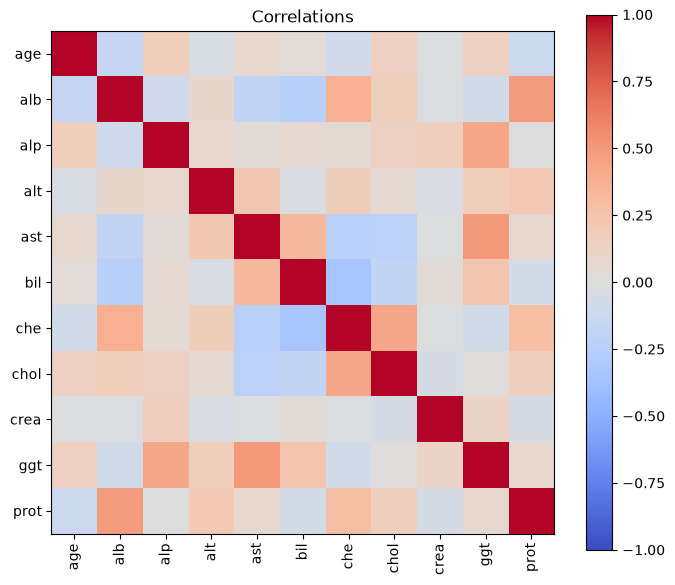

In [8]:
if len(numeric_columns) > 1:
    corr = df[numeric_columns + [target]].select_dtypes("number").corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.columns)
    plt.colorbar(image)
    ax.set_title("Correlations")
    plt.tight_layout()
    plt.show()
    if pd.api.types.is_numeric_dtype(df[target]):
        display(
            corr[target].drop(target)
            .sort_values(key=abs, ascending=False)
            .rename("correlation with the target")
        )

In [9]:
categorical_columns = [
    c for c in df.select_dtypes(exclude="number").columns
    if c not in EXCLUDED_COLUMNS + [target, DATE_COLUMN]
]
for column in categorical_columns[:6]:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts().head(10))


sex: 2 categories


sex
m    371
f    237
Name: count, dtype: int64

,age,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
median per class,,,,,,,,,,,
blood_donor,47.0,42.2,66.70,23.10,24.8,6.9,8.35,5.40,78.00,21.40,72.20
hepatitis,37.0,43.5,34.60,15.20,47.2,13.0,9.51,5.06,72.25,45.55,73.65
fibrosis,51.0,41.0,39.55,34.00,70.0,13.0,8.59,4.58,71.40,72.20,76.10
cirrhosis,56.0,33.0,80.05,5.65,92.9,34.0,3.42,3.87,68.50,96.35,70.00


crea    15.36
bil      8.35
ggt      6.11
ast      5.14
alp      4.88
alt      4.18
chol     0.40
alb      0.29
age      0.25
che     -0.16
prot    -0.40
Name: skewness, dtype: float64

sex,f,m,All
category,,,
blood_donor,215,318,533
hepatitis,4,20,24
fibrosis,8,13,21
cirrhosis,10,20,30
All,237,371,608


sex,f,m
share of each sex,,
blood_donor,0.403,0.597
hepatitis,0.167,0.833
fibrosis,0.381,0.619
cirrhosis,0.333,0.667


ast  ggt     0.50
alb  prot    0.48
che  chol    0.43
alp  ggt     0.42
alb  che     0.38
bil  che    -0.34
Name: correlation between inputs, dtype: float64

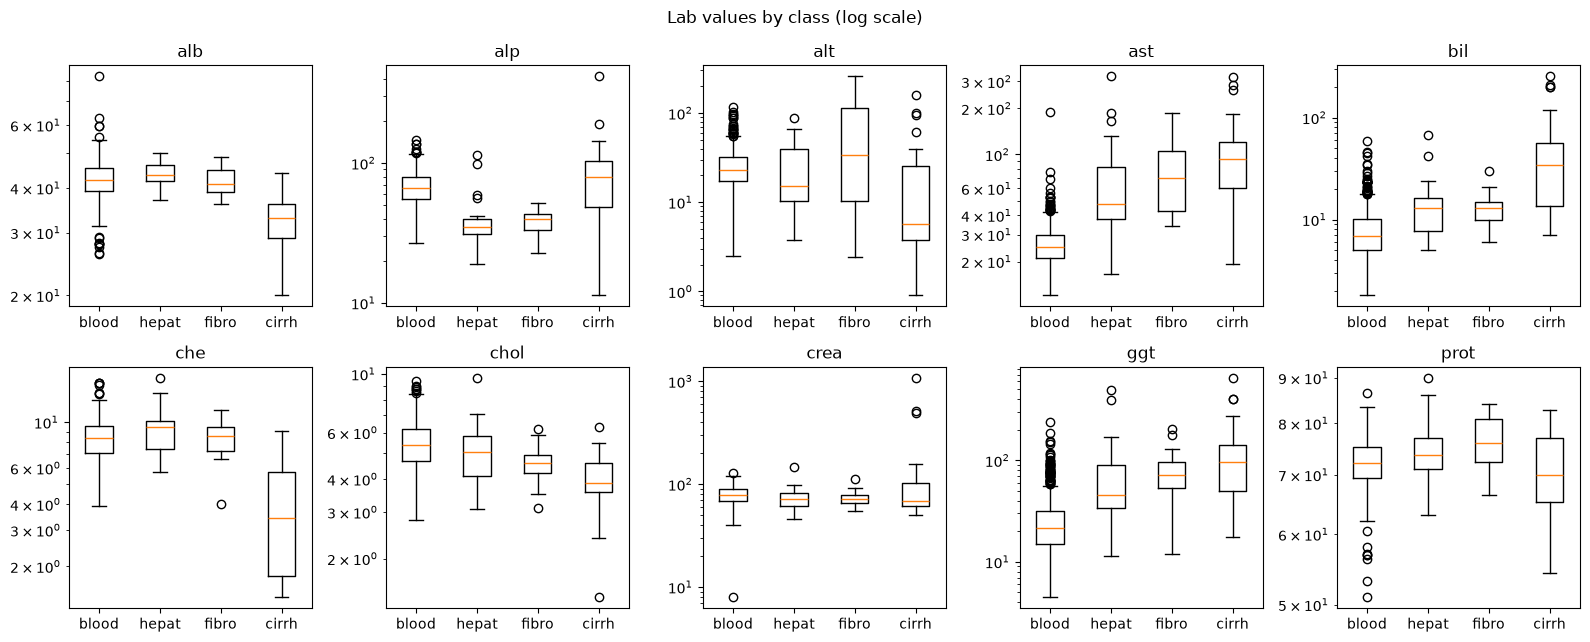

,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
share above the donors' 95th percentile,,,,,,,,,,
blood_donor,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.04,0.05,0.05
hepatitis,0.12,0.04,0.17,0.58,0.17,0.17,0.04,0.04,0.29,0.17
fibrosis,0.05,0.00,0.33,0.81,0.10,0.05,0.00,0.05,0.38,0.29
cirrhosis,0.00,0.27,0.13,0.87,0.70,0.00,0.00,0.27,0.53,0.13


,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
share below the donors' 5th percentile,,,,,,,,,,
blood_donor,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05
hepatitis,0.00,0.71,0.33,0.00,0.00,0.00,0.21,0.17,0.00,0.04
fibrosis,0.00,0.38,0.29,0.00,0.00,0.05,0.10,0.10,0.00,0.00
cirrhosis,0.67,0.17,0.60,0.00,0.00,0.70,0.53,0.17,0.00,0.23


In [10]:
# Lab values by class: medians, skewness and the sex / age profile.
lab_columns = [c for c in numeric_columns if c != "age"]
medians = df.groupby(target)[numeric_columns].median().loc[CLASS_ORDER]
display(medians.round(2).rename_axis("median per class"))
display(
    df[numeric_columns].skew().round(2).sort_values(ascending=False)
    .rename("skewness")
)
display(
    pd.crosstab(df[target], df["sex"], margins=True)
    .loc[CLASS_ORDER + ["All"]]
)
display(
    pd.crosstab(df[target], df["sex"], normalize="index")
    .loc[CLASS_ORDER].round(3).rename_axis("share of each sex")
)

# Strongest linear correlations between inputs.
pairs = df[numeric_columns].corr().stack()
pairs = pairs[
    pairs.index.get_level_values(0) < pairs.index.get_level_values(1)
]
display(
    pairs.sort_values(key=abs, ascending=False).head(6).round(2)
    .rename("correlation between inputs")
)

# Boxplots on a log axis: the lab values are right-skewed.
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for ax, column in zip(axes.ravel(), lab_columns):
    groups = [
        df.loc[df[target].eq(label), column].dropna()
        for label in CLASS_ORDER
    ]
    ax.boxplot(groups, tick_labels=[c[:5] for c in CLASS_ORDER])
    ax.set_yscale("log")
    ax.set_title(column)
plt.suptitle("Lab values by class (log scale)")
plt.tight_layout()
plt.show()

# Share of each class above the 95th percentile of the blood donors.
donors = df[df[target].eq("blood_donor")]
high = df[lab_columns].gt(donors[lab_columns].quantile(0.95))
display(
    high.groupby(df[target]).mean().loc[CLASS_ORDER].round(2)
    .rename_axis("share above the donors' 95th percentile")
)
low = df[lab_columns].lt(donors[lab_columns].quantile(0.05))
display(
    low.groupby(df[target]).mean().loc[CLASS_ORDER].round(2)
    .rename_axis("share below the donors' 5th percentile")
)

**Exploration findings:**

- **Imbalance:** 87.66 % blood donors, 4.93 % cirrhosis, 3.95 % hepatitis and 3.45 % fibrosis. This is addressed with a stratified split, stratified cross-validation, macro F1 as the main metric and class weights.
- **Skewed laboratory values:** creatinine (skewness 15.4), bilirubin (8.4), GGT (6.1), AST (5.1), ALP (4.9) and ALT (4.2) are strongly right-skewed. This motivates trying a **log transform** of the numeric inputs inside the pipeline (section 4); the boxplots use a log axis for the same reason.
- **AST and GGT rise with the stage:** the median AST goes from 24.8 (donors) to 47.2 (hepatitis), 70.0 (fibrosis) and 92.9 (cirrhosis); the median GGT from 21.4 to 45.6, 72.2 and 96.4. AST is above the donors' 95th percentile in 58 % of the hepatitis patients, 81 % of the fibrosis patients and 87 % of the cirrhosis patients.
- **Cirrhosis has its own profile:** low albumin (median 33.0 vs. 42.2 in donors), low cholinesterase (3.42 vs. 8.35), low cholesterol (3.87 vs. 5.40) and high bilirubin (34.0 vs. 6.9). 70 % of the cirrhosis patients are below the donors' 5th percentile of cholinesterase and 67 % below that of albumin. Albumin and cholinesterase are produced by the liver, so this is consistent with a liver that has lost part of its function.
- **Hepatitis and fibrosis look alike:** they have the same median bilirubin (13.0), similar albumin, cholinesterase and creatinine, and both have a low ALP (medians 34.6 and 39.6 vs. 66.7 in donors). They differ mostly in degree (AST, GGT) and in age (median 37 vs. 51 years), so the model is expected to confuse them.
- **Age and sex:** the median age rises from hepatitis (37) to fibrosis (51) and cirrhosis (56); the donors' median is 47. Men are 83 % of the hepatitis patients against 60 % of the donors, but with 24 hepatitis patients this is weak evidence.
- **Little redundancy:** the strongest correlation between two inputs is 0.50 (AST with GGT), so all inputs are kept.

**Preprocessing decisions:** drop the row number and the suspect donors; impute with the median (numeric inputs) or the mode (`sex`); compare scaling alone against a log transform followed by scaling; one-hot encode `sex`. All of this is done inside the `Pipeline`. No rows are removed as outliers.

## 4. Model

A baseline is compared with several models using cross-validation, and the best one is chosen. All preprocessing lives inside a `Pipeline`, so the backend receives raw data and there is no information leakage.

> **Time series:** with `IS_TIME_SERIES = True` the split is chronological (the test set is the most recent data) and cross-validation uses `TimeSeriesSplit`. Never shuffle the temporal order when splitting.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Duplicates removed before splitting, so no row is in both sets.
data = df.drop_duplicates().copy()
if IS_TIME_SERIES and DATE_COLUMN:
    data[DATE_COLUMN] = pd.to_datetime(data[DATE_COLUMN])
    data = data.sort_values(DATE_COLUMN).reset_index(drop=True)

dropped = [TARGET_COLUMN] + EXCLUDED_COLUMNS
dropped += [DATE_COLUMN] if DATE_COLUMN else []
X = data.drop(columns=dropped)
y = data[TARGET_COLUMN]
numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

if IS_TIME_SERIES:
    cut = int(len(X) * 0.8)
    X_train, X_test = X.iloc[:cut], X.iloc[cut:]
    y_train, y_test = y.iloc[:cut], y.iloc[cut:]
    cv = TimeSeriesSplit(n_splits=5)
else:
    stratify = (
        y if TASK_TYPE == "classification" and y.value_counts().min() >= 2
        else None
    )
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=stratify
    )
    cv = (
        StratifiedKFold(5, shuffle=True, random_state=SEED)
        if stratify is not None
        else KFold(5, shuffle=True, random_state=SEED)
    )

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Train: (486, 12)  Test: (122, 12)
Numeric: ['age', 'alb', 'alp', 'alt', 'ast', 'bil', 'che', 'chol', 'crea', 'ggt', 'prot']
Categorical: ['sex']


In [12]:
# Class counts of each split, and the validation scheme.
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import FunctionTransformer

display(pd.DataFrame({
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
}).loc[CLASS_ORDER])

# The smallest class has 17 training patients: one 5-fold split leaves 3-4
# of them per validation fold. Repeating it 3 times with different shuffles
# (15 fits) gives a steadier estimate.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

# Alternative preprocessing: log(1 + x) of the numeric variables before
# scaling, because the lab values are right-skewed (section 3).
log_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
PREPROCESSORS = {"raw": preprocessor, "log": log_preprocessor}

,train,test
category,,
blood_donor,426,107
hepatitis,19,5
fibrosis,17,4
cirrhosis,24,6


In [13]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.svm import SVC

BALANCED = " (balanced)"
base_models = {
    "Logistic regression": LogisticRegression(max_iter=5000),
    "Logistic regression" + BALANCED: LogisticRegression(
        max_iter=5000, class_weight="balanced"
    ),
    "Random Forest" + BALANCED: RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=SEED,
        n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    # SVC has no native probabilities: they are calibrated on internal
    # folds of the training data (Platt scaling), and the predicted class is
    # the most probable one, exactly what the backend reports.
    "SVM RBF" + BALANCED: CalibratedClassifierCV(
        SVC(class_weight="balanced"), ensemble=False
    ),
}
candidates = {
    "Baseline": Pipeline([
        ("prep", preprocessor),
        ("model", DummyClassifier(strategy="most_frequent")),
    ])
}
for model_name, estimator in base_models.items():
    for prep_name, prep in PREPROCESSORS.items():
        candidates[f"{model_name} | {prep_name}"] = Pipeline([
            ("prep", prep), ("model", estimator),
        ])
scoring = "f1_macro"

score_column = f"{scoring} (mean)"
rows = []
for name, pipeline in candidates.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv,
        scoring=["f1_macro", "balanced_accuracy", "accuracy"], n_jobs=1,
    )
    rows.append({
        "model": name,
        score_column: scores["test_f1_macro"].mean(),
        "std": scores["test_f1_macro"].std(),
        "balanced_accuracy (mean)": scores["test_balanced_accuracy"].mean(),
        "accuracy (mean)": scores["test_accuracy"].mean(),
    })
comparison = (
    pd.DataFrame(rows)
    .sort_values(score_column, ascending=False)
    .reset_index(drop=True)
)
display(comparison.round(4))

,model,f1_macro (mean),std,balanced_accuracy (mean),accuracy (mean)
0,Random Forest (balanced) | log,0.6989,0.1053,0.6893,0.9458
1,Logistic regression | log,0.6939,0.0832,0.6843,0.9451
2,SVM RBF (balanced) | log,0.6925,0.0910,0.7004,0.9438
3,Random Forest (balanced) | raw,0.6912,0.1073,0.6807,0.9451
4,Gradient Boosting | raw,0.6792,0.0670,0.6578,0.9410
5,Gradient Boosting | log,0.6749,0.0762,0.6524,0.9410
6,Logistic regression (balanced) | log,0.6326,0.0874,0.7111,0.8882
7,Logistic regression | raw,0.6248,0.0673,0.6081,0.9321
8,Logistic regression (balanced) | raw,0.6099,0.0733,0.6826,0.8792
9,SVM RBF (balanced) | raw,0.5944,0.0725,0.5840,0.9294


**Validation scheme.** The 608 patients are split 80/20 with stratification: **486 for training** (426 donors, 19 hepatitis, 17 fibrosis, 24 cirrhosis) and **122 for testing**. Model selection uses only the training set, with stratified 5-fold cross-validation **repeated 3 times** (15 fits per candidate): with 17 to 24 patients per disease class, a single 5-fold split leaves only 3 to 5 of them in each validation fold, and its score is too noisy.

**Model choice.** Eleven candidates were compared:
- a **baseline** that always predicts the most frequent class;
- **logistic regression**, with and without balanced class weights;
- **Random Forest** (Breiman, 2001) with balanced class weights;
- **Gradient Boosting** (Friedman, 2001);
- a support vector machine (**SVM**) with an RBF kernel and balanced class weights, with calibrated probabilities so that the predicted class is the most probable one;
- each of these five models with two preprocessing variants: `raw` (impute + scale) and `log` (impute + `log(1 + x)` + scale).

| Model | Preprocessing | CV macro F1 | Std | CV balanced accuracy |
|---|---|---|---|---|
| Random Forest (balanced) | log | **0.699** | 0.105 | 0.689 |
| Logistic regression | log | 0.694 | 0.083 | 0.684 |
| SVM RBF (balanced) | log | 0.693 | 0.091 | 0.700 |
| Random Forest (balanced) | raw | 0.691 | 0.107 | 0.681 |
| Gradient Boosting | raw | 0.679 | 0.067 | 0.658 |
| Gradient Boosting | log | 0.675 | 0.076 | 0.652 |
| Logistic regression (balanced) | log | 0.633 | 0.087 | 0.711 |
| Logistic regression | raw | 0.625 | 0.067 | 0.608 |
| Logistic regression (balanced) | raw | 0.610 | 0.073 | 0.683 |
| SVM RBF (balanced) | raw | 0.594 | 0.073 | 0.584 |
| Baseline | - | 0.234 | 0.000 | 0.250 |

What the comparison shows:
- **Every model clearly beats the baseline** in macro F1 (0.234). In accuracy the gap looks small, about 0.945 for the best models against 0.877 for the baseline: accuracy hides most of the difference.
- **The log transform matters for the models that depend on distances and linear effects:** logistic regression goes from 0.625 to 0.694 and the SVM from 0.594 to 0.693. For the tree ensembles it makes no real difference (0.691 vs. 0.699 for Random Forest), as expected: a tree only uses the order of the values.
- **Class weights are a trade-off:** in logistic regression (log preprocessing) they raise the balanced accuracy (0.684 to 0.711) but lower the macro F1 (0.694 to 0.633) and the accuracy (0.945 to 0.888), which is consistent with more donors being flagged as patients.
- **The top three are tied.** Random Forest, logistic regression and the SVM differ by less than 0.007 in macro F1, while the standard deviation across folds is about 0.08 to 0.11. The data cannot tell which one is better. **Random Forest (balanced) with log preprocessing** is selected by the rule fixed beforehand (highest mean cross-validated macro F1), not because it is demonstrably superior.

**Hyperparameter tuning.** **Only the selected model was tuned**; the other candidates were compared with the fixed settings listed above. `RandomizedSearchCV` evaluated 20 of the 72 possible combinations with the same repeated cross-validation, on the training set only:
- **Searched hyperparameters:** number of trees (200, 400), maximum depth (none, 5, 10), minimum samples per leaf (1, 2, 4), features considered per split (`sqrt`, 0.5) and `class_weight` (`balanced`, `balanced_subsample`).
- **Result:** **the search returned the starting configuration** (200 trees, no depth limit, `min_samples_leaf=1`, `max_features="sqrt"`, `class_weight="balanced"`): the cross-validated macro F1 is 0.699 before and after tuning. The five best combinations of the search are between 0.688 and 0.699, with standard deviations across folds of 0.07 to 0.11, so **they are tied within fold noise**, like the top three candidates of the comparison. **Tuning did not improve the model**, so the initial configuration is kept. With so few patients per class, the hyperparameters matter less than the amount of data.

In [14]:
BEST = comparison.loc[~comparison["model"].eq("Baseline"), "model"].iloc[0]
print("Chosen model:", BEST)
final_pipeline = candidates[BEST]
final_pipeline.fit(X_train, y_train)

Chosen model: Random Forest (balanced) | log


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['blood_donor','cirrhosis','fibrosis','hepatitis']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['age','sex','alb',...,'crea','ggt','prot']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthroug

In [15]:
# Hyperparameter tuning of the chosen model: cross-validation on TRAIN only.
from sklearn.model_selection import RandomizedSearchCV

SEARCH_SPACES = {
    "Logistic regression": {
        "model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30],
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.5],
        "model__class_weight": ["balanced", "balanced_subsample"],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200, 400],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.8, 1.0],
    },
    "SVM RBF": {
        "model__estimator__C": [0.1, 0.3, 1, 3, 10, 30],
        "model__estimator__gamma": ["scale", 0.01, 0.03, 0.1],
        "model__estimator__class_weight": [None, "balanced"],
    },
}
PREPROCESSING = BEST.split(" | ")[1]
space = SEARCH_SPACES[BEST.split(" | ")[0].removesuffix(BALANCED)]

search = RandomizedSearchCV(
    final_pipeline,
    space,
    n_iter=min(20, int(np.prod([len(v) for v in space.values()]))),
    cv=cv,
    scoring=scoring,
    random_state=SEED,
    n_jobs=1,
)
search.fit(X_train, y_train)
untuned = comparison.loc[comparison["model"].eq(BEST), score_column].iloc[0]
print(
    f"{scoring} CV untuned: {untuned:.4f} | tuned: {search.best_score_:.4f}"
)
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(
    results[
        [c for c in results if c.startswith("param_")]
        + ["mean_test_score", "std_test_score"]
    ].head(5).round(4)
)
if search.best_score_ > untuned:
    final_pipeline = search.best_estimator_
    used = search.best_params_
else:
    # Keep the untuned candidate and record the settings that matter.
    used = {key: final_pipeline.get_params()[key] for key in space}
HYPERPARAMETERS = {
    key.removeprefix("model__").removeprefix("estimator__"): value
    for key, value in used.items()
}
print("Preprocessing:", PREPROCESSING)
print("Hyperparameters used:", HYPERPARAMETERS)

f1_macro CV untuned: 0.6989 | tuned: 0.6989


,param_model__n_estimators,param_model__min_samples_leaf,param_model__max_features,param_model__max_depth,param_model__class_weight,mean_test_score,std_test_score
3,200,1,sqrt,None,balanced,0.6989,0.1053
14,400,4,sqrt,None,balanced,0.6887,0.0735
4,200,4,sqrt,10,balanced,0.6884,0.0761
0,200,4,sqrt,None,balanced,0.6884,0.0761
17,400,1,sqrt,5,balanced_subsample,0.6883,0.0912


Preprocessing: log
Hyperparameters used: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced'}


## 5. Evaluation

The chosen model is evaluated on the held-out test set, which was not used for training, model selection or tuning. Any other model scored on the test set (the baseline and the untuned candidate) is shown for reference only. The methods note below records that an earlier run of this notebook also scored an SVM candidate, since replaced, on this test set.

              precision    recall  f1-score   support

 blood_donor       0.98      0.99      0.99       107
   cirrhosis       0.57      0.67      0.62         6
    fibrosis       0.50      0.50      0.50         4
   hepatitis       0.33      0.20      0.25         5

    accuracy                           0.93       122
   macro avg       0.60      0.59      0.59       122
weighted avg       0.92      0.93      0.92       122



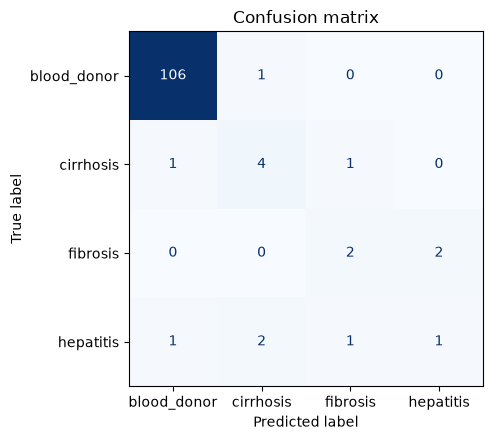

accuracy             0.9262
f1_macro             0.5879
balanced_accuracy    0.5893
precision_macro      0.5966
recall_macro         0.5893
Name: test metrics, dtype: float64

Baseline f1_macro on test: 0.2336


In [16]:
from sklearn import metrics

predictions = final_pipeline.predict(X_test)

if TASK_TYPE == "classification":
    test_metrics = {
        "accuracy": metrics.accuracy_score(y_test, predictions),
        "f1_macro": metrics.f1_score(y_test, predictions, average="macro"),
        "balanced_accuracy": metrics.balanced_accuracy_score(
            y_test, predictions
        ),
        "precision_macro": metrics.precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "recall_macro": metrics.recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    }
    print(metrics.classification_report(
        y_test, predictions, zero_division=0
    ))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    metrics.ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title("Confusion matrix")
    plt.tight_layout()
    plt.show()
else:
    test_metrics = {
        "rmse": metrics.mean_squared_error(y_test, predictions) ** 0.5,
        "mae": metrics.mean_absolute_error(y_test, predictions),
        "r2": metrics.r2_score(y_test, predictions),
    }
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(y_test, predictions, alpha=0.4)
    limits = [
        min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max()),
    ]
    ax[0].plot(limits, limits, "r--")
    ax[0].set_xlabel("Actual")
    ax[0].set_ylabel("Predicted")
    ax[0].set_title("Actual vs. predicted")
    ax[1].hist(y_test - predictions, bins=40)
    ax[1].set_title("Residual distribution")
    plt.tight_layout()
    plt.show()

test_metrics = {k: round(float(v), 4) for k, v in test_metrics.items()}
display(pd.Series(test_metrics, name="test metrics"))

# Baseline on the same test set, to check the model really adds value.
baseline = candidates["Baseline"].fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
if TASK_TYPE == "classification":
    baseline_score = metrics.f1_score(
        y_test, baseline_predictions, average="macro"
    )
    print("Baseline f1_macro on test:", round(baseline_score, 4))
else:
    baseline_score = (
        metrics.mean_squared_error(y_test, baseline_predictions) ** 0.5
    )
    print("Baseline RMSE on test:", round(baseline_score, 4))

In [17]:
# Confusion matrix in clinical order (rows: actual, columns: predicted).
confusion = pd.DataFrame(
    metrics.confusion_matrix(y_test, predictions, labels=CLASS_ORDER),
    index=CLASS_ORDER, columns=CLASS_ORDER,
).rename_axis(index="actual", columns="predicted")
display(confusion)

# The API reports the class with the highest probability: check that it is
# the same class `predict` returns on the test set.
probabilities = pd.DataFrame(
    final_pipeline.predict_proba(X_test),
    index=X_test.index, columns=final_pipeline.classes_,
)
top_class = probabilities.idxmax(axis=1)
print(
    "Test rows where the most probable class differs from predict():",
    int((top_class.to_numpy() != predictions).sum()), "of", len(X_test),
)
print(
    "Macro F1 of the most probable class:",
    round(metrics.f1_score(y_test, top_class, average="macro"), 4),
)

# Screening view: blood donor vs. any liver disease.
actual_sick = y_test.ne("blood_donor")
predicted_sick = pd.Series(predictions, index=y_test.index).ne("blood_donor")
print("Patients with disease in test:", int(actual_sick.sum()))
print("  detected as some disease:", int((actual_sick & predicted_sick).sum()))
print("  predicted as blood donor:", int((actual_sick & ~predicted_sick).sum()))
print("Blood donors in test:", int((~actual_sick).sum()))
print("  flagged as disease:", int((~actual_sick & predicted_sick).sum()))

# Every misclassified test patient.
wrong = X_test.assign(
    actual=y_test, predicted=predictions,
    confidence=probabilities.max(axis=1).round(2),
)
wrong = wrong[wrong["actual"].ne(wrong["predicted"])]
print("Misclassified test patients:", len(wrong), "of", len(X_test))
display(wrong[["actual", "predicted", "confidence"] + X.columns.tolist()])

# Baseline balanced accuracy and the untuned candidate, for reference only.
print(
    "Baseline balanced accuracy on test:",
    round(metrics.balanced_accuracy_score(y_test, baseline_predictions), 4),
    "| accuracy:",
    round(metrics.accuracy_score(y_test, baseline_predictions), 4),
)
untuned_predictions = candidates[BEST].fit(X_train, y_train).predict(X_test)
print(
    "Untuned", BEST, "macro F1 on test:",
    round(metrics.f1_score(y_test, untuned_predictions, average="macro"), 4),
)

predicted,blood_donor,hepatitis,fibrosis,cirrhosis
actual,,,,
blood_donor,106,0,0,1
hepatitis,1,1,1,2
fibrosis,0,2,2,0
cirrhosis,1,0,1,4


Test rows where the most probable class differs from predict(): 0 of 122
Macro F1 of the most probable class: 0.5879
Patients with disease in test: 15
  detected as some disease: 13
  predicted as blood donor: 2
Blood donors in test: 107
  flagged as disease: 1
Misclassified test patients: 9 of 122


,actual,predicted,confidence,age,sex,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
552,hepatitis,cirrhosis,0.52,58,m,43.0,99.1,12.2,63.2,13.0,5.95,6.15,147.3,491.0,65.6
551,hepatitis,cirrhosis,0.88,56,m,37.0,114.0,27.8,324.0,67.0,5.75,3.09,97.7,392.2,77.3
559,fibrosis,hepatitis,0.56,46,m,45.0,26.9,23.1,125.0,17.0,6.97,4.01,60.5,72.2,73.0
548,hepatitis,fibrosis,0.41,46,m,48.0,59.5,11.6,39.0,7.0,16.41,4.65,66.4,158.2,72.7
584,cirrhosis,blood_donor,0.59,46,m,35.0,109.6,2.3,19.2,11.0,7.10,4.10,1079.1,105.6,69.1
596,cirrhosis,fibrosis,0.66,65,m,NaN,NaN,40.0,54.0,13.0,7.50,NaN,70.0,107.0,79.0
573,fibrosis,hepatitis,0.40,68,f,43.0,22.9,5.0,42.1,12.0,7.29,4.89,80.9,11.9,76.1
547,hepatitis,blood_donor,0.66,44,m,49.0,27.3,40.2,31.1,13.0,8.91,4.07,81.5,27.6,72.8
527,blood_donor,cirrhosis,0.48,63,f,27.8,85.7,25.4,38.9,4.2,6.06,3.96,63.0,46.0,56.9


Baseline balanced accuracy on test: 0.25 | accuracy: 0.877


Untuned

 Random Forest (balanced) | log macro F1 on test: 0.5879


In [18]:
# The test set has only 4-6 patients per disease class, so one patient moves
# a recall by 17-25 points. Out-of-fold predictions on the TRAINING set give
# a second, larger view (every training patient is predicted by a model that
# did not see it). They are not a substitute for the test set: the
# hyperparameters were chosen on these same folds, so they are optimistic.
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(
    clone(final_pipeline), X_train, y_train,
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
)
print(metrics.classification_report(
    y_train, oof, labels=CLASS_ORDER, zero_division=0
))
display(
    pd.DataFrame(
        metrics.confusion_matrix(y_train, oof, labels=CLASS_ORDER),
        index=CLASS_ORDER, columns=CLASS_ORDER,
    ).rename_axis(index="actual (train, out-of-fold)", columns="predicted")
)
print(
    "Out-of-fold macro F1:",
    round(metrics.f1_score(y_train, oof, average="macro"), 4),
    "| balanced accuracy:",
    round(metrics.balanced_accuracy_score(y_train, oof), 4),
)
oof_sick = pd.Series(oof, index=y_train.index).ne("blood_donor")
train_sick = y_train.ne("blood_donor")
print(
    "Out-of-fold, donor vs. disease: detected",
    int((train_sick & oof_sick).sum()), "of", int(train_sick.sum()),
    "patients with disease; flagged",
    int((~train_sick & oof_sick).sum()), "of", int((~train_sick).sum()),
    "donors",
)

              precision    recall  f1-score   support

 blood_donor       0.97      1.00      0.98       426
   hepatitis       0.67      0.53      0.59        19
    fibrosis       0.55      0.35      0.43        17
   cirrhosis       0.80      0.83      0.82        24

    accuracy                           0.95       486
   macro avg       0.75      0.68      0.70       486
weighted avg       0.94      0.95      0.94       486



predicted,blood_donor,hepatitis,fibrosis,cirrhosis
"actual (train, out-of-fold)",,,,
blood_donor,424,0,0,2
hepatitis,4,10,4,1
fibrosis,4,5,6,2
cirrhosis,3,0,1,20


Out-of-fold macro F1: 0.7045 | balanced accuracy: 0.677
Out-of-fold, donor vs. disease: detected 49 of 60 patients with disease; flagged 2 of 426 donors


,drop in macro F1,std
ast,0.2685,0.0325
alp,0.0464,0.0158
che,0.0373,0.0172
age,0.0189,0.0150
ggt,0.0149,0.0100
prot,0.0085,0.0034
alt,0.0066,0.0037
bil,0.0038,0.0044
sex,0.0000,0.0000
crea,-0.0004,0.0031


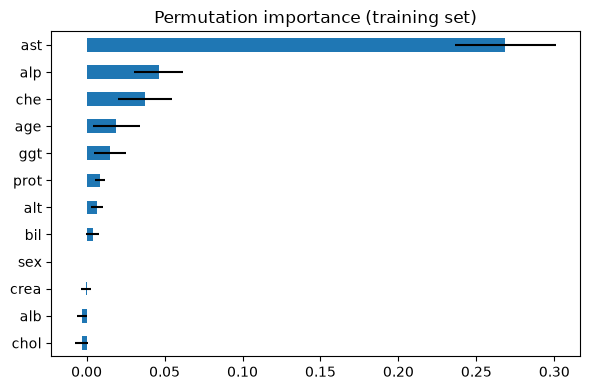

num__ast      0.1667
num__che      0.1489
num__alp      0.1069
num__ggt      0.0953
num__age      0.0865
num__bil      0.0831
num__alb      0.0830
num__alt      0.0685
num__chol     0.0562
num__prot     0.0513
num__crea     0.0378
cat__sex_m    0.0083
cat__sex_f    0.0077
Name: impurity importance, dtype: float64

In [19]:
# Feature importance: permutation importance works for any model. Each
# input column is shuffled and the drop in macro F1 is measured. It is
# computed on the training set (the test set is too small for it), so it
# describes what the fitted model relies on, not generalization.
from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    final_pipeline, X_train, y_train, scoring="f1_macro",
    n_repeats=20, random_state=SEED, n_jobs=1,
)
importance = pd.DataFrame({
    "drop in macro F1": permutation.importances_mean,
    "std": permutation.importances_std,
}, index=X_train.columns).sort_values("drop in macro F1")
display(importance.iloc[::-1].round(4))
importance["drop in macro F1"].plot(
    kind="barh", figsize=(6, 4), xerr=importance["std"],
    title="Permutation importance (training set)",
)
plt.tight_layout()
plt.show()

estimator = final_pipeline.named_steps["model"]
if hasattr(estimator, "feature_importances_"):
    display(
        pd.Series(
            estimator.feature_importances_,
            index=final_pipeline.named_steps["prep"].get_feature_names_out(),
        ).sort_values(ascending=False).round(4).rename("impurity importance")
    )
elif hasattr(estimator, "coef_"):
    display(
        pd.DataFrame(
            estimator.coef_, index=estimator.classes_,
            columns=final_pipeline.named_steps["prep"].get_feature_names_out(),
        ).T.round(2).rename_axis("coefficients (scaled inputs)")
    )

In [20]:
# The 7 "suspect" donors that were set aside: what does the model say?
# There is no ground truth for them, so this is only a qualitative check.
suspect_probabilities = pd.DataFrame(
    final_pipeline.predict_proba(suspects[X.columns]),
    index=suspects.index, columns=final_pipeline.classes_,
)[CLASS_ORDER].round(2)
display(suspect_probabilities.assign(
    predicted=final_pipeline.predict(suspects[X.columns])
))

,blood_donor,hepatitis,fibrosis,cirrhosis,predicted
533,0.38,0.03,0.14,0.45,cirrhosis
534,0.70,0.01,0.01,0.28,blood_donor
535,0.66,0.02,0.04,0.28,blood_donor
536,0.55,0.16,0.20,0.08,blood_donor
537,0.44,0.16,0.12,0.29,blood_donor
538,0.28,0.00,0.10,0.61,cirrhosis
539,0.19,0.00,0.26,0.54,cirrhosis


**Interpretation.** On the test set (122 patients not used for training) the model reaches **macro F1 0.588**, **balanced accuracy 0.589** and accuracy 0.926, against a baseline with macro F1 **0.234**, balanced accuracy 0.250 and accuracy 0.877. The model is far better than the baseline, but its accuracy is only 5 points above always answering "blood donor": almost all of its value is in the minority classes, and there it is modest.

**These numbers are very uncertain.** The test set has **6 cirrhosis, 5 hepatitis and 4 fibrosis patients**. One patient more or less changes a class recall by 17 to 25 points, so the per-class figures below should be read as counts, not as reliable rates.

| Class | Precision | Recall | F1 | Test patients |
|---|---|---|---|---|
| blood_donor | 0.98 | 0.99 | 0.99 | 107 |
| hepatitis | 0.33 | 0.20 | 0.25 | 5 |
| fibrosis | 0.50 | 0.50 | 0.50 | 4 |
| cirrhosis | 0.57 | 0.67 | 0.62 | 6 |

**Error analysis (confusion matrix):**
- **Donor vs. patient is separated much better than the stage.** 13 of the 15 patients with disease were assigned to some disease class, and only 1 of the 107 donors was flagged (as cirrhosis). 2 patients were predicted as blood donors (1 hepatitis, 1 cirrhosis): for a screening use these are the costly errors.
- **The stage is often wrong.** Of the 13 detected patients only 7 received the right stage (1 of 5 hepatitis, 2 of 4 fibrosis, 4 of 6 cirrhosis). Hepatitis is the worst class: 2 patients were predicted as cirrhosis, 1 as fibrosis and 1 as donor. Fibrosis and hepatitis are confused with each other, as the exploration anticipated.
- **The individual errors are understandable.** The hepatitis patient predicted as cirrhosis with probability 0.88 has an AST of 324 and a bilirubin of 67, both well above the cirrhosis medians (92.9 and 34.0). The hepatitis patient predicted as donor has an AST of 31.1, close to the donors' median (24.8). The cirrhosis patient predicted as donor has an AST below the donors' median (19.2) together with the highest creatinine of the dataset (1079.1). The cirrhosis patient predicted as fibrosis has three missing values (`alb`, `alp`, `chol`), replaced by medians. The flagged donor has a low albumin (27.8), as in the cirrhosis group, and a low total protein (56.9).
- **The predicted class is always the most probable one** (0 disagreements in 122), which is what the backend reports.

**A second view with more patients.** Out-of-fold predictions on the training set (each of the 486 patients is predicted by a model that did not see it) give macro F1 0.705 and balanced accuracy 0.677, with F1 0.98 for donors, 0.82 for cirrhosis, 0.59 for hepatitis and 0.43 for fibrosis. There, 49 of the 60 patients with disease were detected and 2 of the 426 donors were flagged. The pattern is the same as in the test set (cirrhosis is the best recognized stage, and fibrosis and hepatitis are confused), but this view is optimistic because the model was chosen on those same patients.

**Test vs. cross-validation.** The test macro F1 (0.588) is below the cross-validated estimate (0.699), a gap of about one standard deviation across folds (0.105). This is compatible with the noise of such a small test set, and also with some optimism from choosing the best of eleven candidates. The honest summary is a macro F1 roughly between 0.59 and 0.70, with wide uncertainty.

**Methods note.** An earlier run of this notebook evaluated a different SVM candidate on the test set: it used `SVC(probability=True)`, and its predicted class did not always match its most probable class. That candidate was replaced by the SVM with calibrated probabilities described in section 4, the comparison was repeated, and the selection rule (highest cross-validated macro F1 on the training set) was applied unchanged. The test set was therefore not used to choose the model, but it was looked at more than once.

**Feature importance.** Shuffling **AST** lowers the macro F1 of the fitted model by 0.27, far more than any other input; ALP (0.05), cholinesterase (0.04), age (0.02) and GGT (0.01) follow. The impurity importance of the forest puts the same three inputs first (AST 0.17, cholinesterase 0.15, ALP 0.11), with a flatter profile. This matches the exploration: AST separates patients from donors, cholinesterase marks cirrhosis and a low ALP marks hepatitis and fibrosis. `sex` and creatinine contribute almost nothing. The permutation importance is measured on the training set, so it describes what the model uses, not how well it generalizes.

**The suspect donors.** For the 7 people set aside, the model predicts cirrhosis for 3 and blood donor for 4, the latter with donor probabilities between 0.44 and 0.70 (the median training patient, a typical donor profile, gets 0.98). The model does not treat them as ordinary donors, which supports the decision not to merge them into that class. There is no ground truth to score this check.

**Possible causes of error:** very few patients per stage; hepatitis, fibrosis and cirrhosis are points on a continuous progression, so neighboring stages overlap; a routine panel lacks the markers used for staging; and the donors and the patients may come from different populations, a difference the model cannot distinguish from the disease itself.

## Export for the backend

In [21]:
joblib.dump(final_pipeline, ARTIFACTS / f"{MODEL_NAME}.joblib")

# Typical input: becomes the `default_input` of the backend adapter.
example = X_train.median(numeric_only=True).round(3).to_dict()
example["age"] = int(example["age"])
for column in categorical_features:
    example[column] = X_train[column].mode().iloc[0]

meta = {
    "model": BEST,
    "hyperparameters": HYPERPARAMETERS,
    "preprocessing": PREPROCESSING,
    "task": TASK_TYPE,
    "features": X.columns.tolist(),
    "test_metrics": test_metrics,
    "baseline_test_f1_macro": round(float(baseline_score), 4),
    "test_support": {
        label: int(count) for label, count in y_test.value_counts().items()
    },
    "default_input": example,
    "sklearn_version": sklearn.__version__,
}
if TASK_TYPE == "classification":
    meta["classes"] = sorted(y.unique().tolist())
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

print(f"Saved artifacts/{MODEL_NAME}.joblib and {meta_path.name}")
size_kb = (ARTIFACTS / f"{MODEL_NAME}.joblib").stat().st_size / 1024
print(f"Artifact size: {size_kb:.0f} KB")
example_frame = pd.DataFrame([example])[X.columns]
print(
    "Prediction for the default input:",
    final_pipeline.predict(example_frame)[0],
    dict(zip(
        final_pipeline.classes_,
        final_pipeline.predict_proba(example_frame)[0].round(4).tolist(),
    )),
)
print("\nCopy to backend/models/<package>/ (schema.py / default_input):")
print(json.dumps(example, indent=2, default=str))

Saved artifacts/hepatitis.joblib and hepatitis.meta.json
Artifact size: 1289 KB
Prediction for the default input: blood_donor {'blood_donor': 0.98, 'cirrhosis': 0.005, 'fibrosis': 0.0, 'hepatitis': 0.015}

Copy to backend/models/<package>/ (schema.py / default_input):
{
  "age": 46,
  "alb": 41.85,
  "alp": 65.4,
  "alt": 22.5,
  "ast": 26.05,
  "bil": 7.45,
  "che": 8.225,
  "chol": 5.29,
  "crea": 76.45,
  "ggt": 23.25,
  "prot": 72.0,
  "sex": "m"
}


## 6. Conclusion

A Random Forest with balanced class weights estimates the hepatitis C category from 10 routine laboratory values, age and sex with a **test macro F1 of 0.59** and a balanced accuracy of 0.59, against 0.23 and 0.25 for the baseline. It separates blood donors from patients well (13 of 15 patients detected and 1 of 107 donors flagged in the test set), but it **cannot stage the disease reliably**: only 7 of those 13 patients received the right stage, and hepatitis is the worst recognized class. The inputs it relies on most (AST, cholinesterase, ALP) agree with the exploration. It is a **screening aid that produces an estimate, not a diagnostic tool**.

**Limitations:**
- Only 21 to 30 patients per disease stage, and 4 to 6 of each in the test set: every per-class figure is very uncertain.
- The three best candidates were tied in cross-validation; the choice of Random Forest is not statistically supported.
- A single data source, in which patients and donors may differ in more than the disease (for example in how and where the samples were taken), and no external validation.
- The 7 suspect donors were excluded, so the model was neither trained nor evaluated on that group.
- Missing ALP values occur only in patients with disease; they are imputed with the median, which makes those patients look more like donors.
- The default input of the voice command is the median training patient, a healthy profile: without data the answer is always "blood donor".

**Future improvements:**
- More patients per stage; this is the main limit.
- A two-step model: first donor vs. patient, then the stage among patients.
- Treat the stage as an ordinal target.
- Tune the decision threshold to favor sensitivity (not missing patients) over precision.
- Evaluate with repeated or nested cross-validation instead of one small test set, and check the probability calibration.

**Voice commands for this model:** *"JarvisTEC, hepatitis type"*, *"JarvisTEC, type of hepatitis"*, *"JarvisTEC, classify hepatitis"*

### References

- Hoffmann, G., Bietenbeck, A., Lichtinghagen, R., & Klawonn, F. (2018). Using machine learning techniques to generate laboratory diagnostic pathways—a case study. *Journal of Laboratory and Precision Medicine, 3*, 58.
- Lichtinghagen, R., Klawonn, F., & Hoffmann, G. (2020). *HCV data* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5D612
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232. https://doi.org/10.1214/aos/1013203451
- He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.